# Домашнее задание 1. Персональные рекомендации для Retailrocket

В работе сравниваются пять самостоятельно реализованных моделей и формируются персональные рекомендации top-10 товаров. Используется [Retailrocket Recommender System Dataset](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset). В наборе записаны события интернет-магазина, а не явные оценки. Поэтому релевантность определяется фактом взаимодействия с товаром в будущем временном окне.

Рекомендуются товары, с которыми пользователь не взаимодействовал в обучающем периоде. Повторные события пары пользователь - товар влияют на силу обучающего сигнала, но в оценочной релевантности один товар учитывается один раз

## 1. Импорты и воспроизводимость

In [1]:
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)


## 2. Загрузка и описание данных

In [2]:
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/retailrocket/ecommerce-dataset")

events = pd.read_csv(DATA_DIR / "events.csv")
items = pd.read_csv(DATA_DIR / "item_properties_part1.csv")
items2 = pd.read_csv(DATA_DIR / "item_properties_part2.csv")
category_tree = pd.read_csv(DATA_DIR / "category_tree.csv")

print("events:", events.shape)
print("item properties:", items.shape, items2.shape)
print("category tree:", category_tree.shape)

events.head()

events: (2756101, 5)
item properties: (10999999, 4) (9275903, 4)
category tree: (1669, 2)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


### Поля и смысл данных

- `events.csv`: `visitorid` - посетитель; `itemid` - товар; `event` - просмотр (`view`), добавление в корзину (`addtocart`) или покупка (`transaction`); `timestamp` - время в Unix milliseconds.
- Файлы `item_properties` содержат временные свойства товаров: `timestamp`, `itemid`, `property`, `value`. Для FM используется `categoryid`, доступный к концу train.
- `category_tree.csv` описывает иерархию `categoryid` -> `parentid`.

Релевантный объект - уникальный товар, с которым произошло взаимодействие в оцениваемом периоде. Веса `view=1`, `addtocart=3`, `transaction=5` используются только в обучающей матрице; критерий релевантности validation и test одинаков для всех моделей


## 3. Очистка и формирование выборки

In [3]:
print(events.dtypes)
print(events["event"].value_counts(dropna=False))
print(events.isna().sum())

# Для рекомендаций используем взаимодействия с товаром
# Удаляем строки без ключевых полей и точные дубликаты
events = events.dropna(subset=["timestamp", "visitorid", "itemid", "event"]).copy()
events = events.drop_duplicates()

# В Retailrocket timestamp задан в миллисекундах Unix time
events["timestamp"] = pd.to_datetime(
    events["timestamp"], unit="ms", utc=True
)

events = events.sort_values("timestamp").reset_index(drop=True)

print("После очистки:", events.shape)
print(events["event"].value_counts())
print("Период:", events["timestamp"].min(), "—", events["timestamp"].max())
print("Пользователей:", events["visitorid"].nunique())
print("Товаров:", events["itemid"].nunique())

timestamp          int64
visitorid          int64
event             object
itemid             int64
transactionid    float64
dtype: object
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64
После очистки: (2755641, 5)
event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64
Период: 2015-05-03 03:00:04.384000+00:00 — 2015-09-18 02:59:47.788000+00:00
Пользователей: 1407580
Товаров: 235061


### Воспроизводимая подвыборка

После удаления строк с пропущенными ключами и точных дубликатов события сортируются по времени; в выборку входят последние 1 650 000 строк. Это детерминированный временной срез. Такой отбор сохраняет недавнюю активность и ограничивает размер эксперимента, но может сильнее представлять пользователей и товары, активные ближе к концу периода. Далее проверяются итоговый объём и число пользователей и товаров

In [4]:
# Сортируем уже очищенные события по времени
events = events.sort_values("timestamp").reset_index(drop=True)

N_KEEP = 1_650_000
sample = events.tail(N_KEEP).copy().reset_index(drop=True)

print("Взаимодействий:", len(sample))
print("Период:", sample["timestamp"].min(), "—", sample["timestamp"].max())
print("Пользователей:", sample["visitorid"].nunique())
print("Товаров:", sample["itemid"].nunique())

assert 100_000 <= len(sample) <= 2_000_000
assert sample["visitorid"].nunique() >= 1_000
assert sample["itemid"].nunique() >= 1_000

Взаимодействий: 1650000
Период: 2015-06-26 01:32:47.809000+00:00 — 2015-09-18 02:59:47.788000+00:00
Пользователей: 881235
Товаров: 191303


### EDA выборки

In [5]:
n_events = len(sample)
n_users = sample["visitorid"].nunique()
n_items = sample["itemid"].nunique()

# Число уникальных пар пользователь—товар
n_pairs = sample[["visitorid", "itemid"]].drop_duplicates().shape[0]

density = n_pairs / (n_users * n_items)
sparsity = 1 - density

print(f"Событий: {n_events:,}")
print(f"Пользователей: {n_users:,}")
print(f"Товаров: {n_items:,}")
print(f"Уникальных пар пользователь—товар: {n_pairs:,}")
print(f"Плотность матрицы: {density:.8f}")
print(f"Разреженность матрицы: {sparsity:.4%}")

print("\nТипы событий:")
print(sample["event"].value_counts())

print("\nСобытий на пользователя:")
print(sample.groupby("visitorid", sort=False).size().describe())

print("\nСобытий на товар:")
print(sample.groupby("itemid", sort=False).size().describe())

Событий: 1,650,000
Пользователей: 881,235
Товаров: 191,303
Уникальных пар пользователь—товар: 1,300,074
Плотность матрицы: 0.00000771
Разреженность матрицы: 99.9992%

Типы событий:
event
view           1594671
addtocart        41817
transaction      13512
Name: count, dtype: int64

Событий на пользователя:
count    881235.000000
mean          1.872372
std          12.239498
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        6531.000000
dtype: float64

Событий на товар:
count    191303.000000
mean          8.625061
std          26.405241
min           1.000000
25%           1.000000
50%           2.000000
75%           7.000000
max        3397.000000
dtype: float64


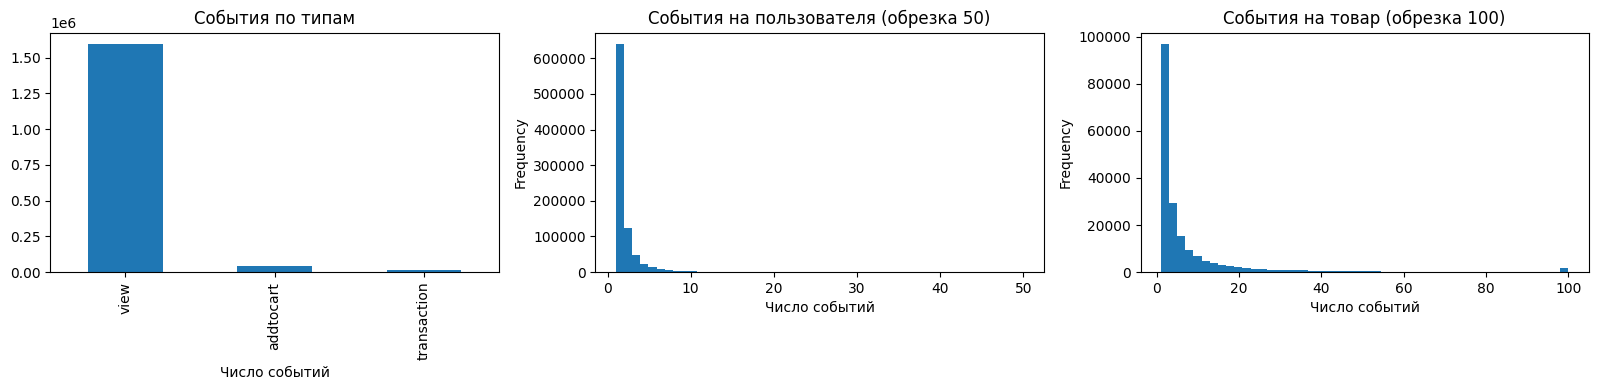

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sample["event"].value_counts().plot.bar(ax=axes[0], title="События по типам")
sample.groupby("visitorid").size().clip(upper=50).plot.hist(bins=50, ax=axes[1], title="События на пользователя (обрезка 50)")
sample.groupby("itemid").size().clip(upper=100).plot.hist(bins=50, ax=axes[2], title="События на товар (обрезка 100)")
for ax in axes: ax.set_xlabel("Число событий")
plt.tight_layout()
plt.show()

## 4. Временное разбиение и cold-start срезы

Хронологическое разбиение: первые 80% событий - train, следующие 10% - validation, последние 10% - test. Полный test сохраняется. Дополнительно выделяются события знакомых пользователей и товаров

In [7]:
sample = sample.sort_values("timestamp").reset_index(drop=True)

times = sample["timestamp"]
val_cut = times.iloc[int(len(times) * 0.80)]
test_cut = times.iloc[int(len(times) * 0.90)]

train = sample[sample["timestamp"] < val_cut].copy()
valid_full = sample[
    (sample["timestamp"] >= val_cut) &
    (sample["timestamp"] < test_cut)
].copy()
test_full = sample[sample["timestamp"] >= test_cut].copy()

print("Train:", len(train), train["timestamp"].min(), "—", train["timestamp"].max())
print("Validation:", len(valid_full), valid_full["timestamp"].min(), "—", valid_full["timestamp"].max())
print("Test full:", len(test_full), test_full["timestamp"].min(), "—", test_full["timestamp"].max())

assert len(sample) == 1_650_000
assert len(test_full) == 165_000
assert train["timestamp"].max() < valid_full["timestamp"].min()
assert valid_full["timestamp"].max() < test_full["timestamp"].min()

Train: 1320000 2015-06-26 01:32:47.809000+00:00 — 2015-08-30 16:51:01.558000+00:00
Validation: 165000 2015-08-30 16:51:03.488000+00:00 — 2015-09-08 22:27:25.873000+00:00
Test full: 165000 2015-09-08 22:27:28.007000+00:00 — 2015-09-18 02:59:47.788000+00:00


In [8]:
train_users = set(train["visitorid"].unique())
train_items = set(train["itemid"].unique())

test_full = test_full.copy()

is_known_user = test_full["visitorid"].isin(train_users)
is_warm_item = test_full["itemid"].isin(train_items)

test_known_users = test_full[is_known_user].copy()
test_warm = test_full[is_known_user & is_warm_item].copy()
test_cold_items_known_users = test_full[is_known_user & ~is_warm_item].copy()
test_cold_users = test_full[~is_known_user].copy()

print("Полный test:", len(test_full))
print("Знакомые пользователи, все товары:", len(test_known_users))
print("Warm test — знакомые пользователь и товар:", len(test_warm))
print("Холодный товар у знакомого пользователя:", len(test_cold_items_known_users))
print("Холодный пользователь:", len(test_cold_users))

assert len(test_warm) + len(test_cold_items_known_users) == len(test_known_users)
assert len(test_known_users) + len(test_cold_users) == len(test_full)

Полный test: 165000
Знакомые пользователи, все товары: 20306
Warm test — знакомые пользователь и товар: 18210
Холодный товар у знакомого пользователя: 2096
Холодный пользователь: 144694


### Распределение типов событий по периодам


In [9]:
for name, frame in [
    ("train", train),
    ("validation", valid_full),
    ("test_full", test_full),
    ("test_warm", test_warm),
]:
    print(f"\n{name}: {len(frame):,} событий")
    print(frame["event"].value_counts())


train: 1,320,000 событий
event
view           1275720
addtocart        33407
transaction      10873
Name: count, dtype: int64

validation: 165,000 событий
event
view           159437
addtocart        4224
transaction      1339
Name: count, dtype: int64

test_full: 165,000 событий
event
view           159514
addtocart        4186
transaction      1300
Name: count, dtype: int64

test_warm: 18,210 событий
event
view           17281
addtocart        620
transaction      309
Name: count, dtype: int64


## 5. Общая релевантность и train-история

Для метрик повторные события одной пары user-item схлопываются. Из релевантных целей убираются товары, уже виденные этим пользователем в train


In [10]:
def make_relevance(frame):
    pairs = frame[["visitorid", "itemid"]].drop_duplicates()
    return pairs.groupby("visitorid")["itemid"].apply(set).to_dict()

valid_relevance = make_relevance(valid_full)
test_full_relevance = make_relevance(test_full)
test_known_users_relevance = make_relevance(test_known_users)
test_warm_relevance = make_relevance(test_warm)
test_cold_items_known_users_relevance = make_relevance(test_cold_items_known_users)
test_cold_users_relevance = make_relevance(test_cold_users)

# История пользователя в train нужна всем моделям,
# чтобы исключать уже известные товары из рекомендаций
train_seen = (
    train[["visitorid", "itemid"]]
    .drop_duplicates()
    .groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

print("Пользователей в validation:", len(valid_relevance))
print("Пользователей в test_full:", len(test_full_relevance))
print("Пользователей в test_warm:", len(test_warm_relevance))

Пользователей в validation: 96559
Пользователей в test_full: 95827
Пользователей в test_warm: 6240


### Обучающие взаимодействия

Для implicit-моделей типам событий назначены веса: просмотр - 1, корзина - 3, покупка - 5. Это только обучающий сигнал; критерий релевантности на validation/test остаётся единым.


In [11]:
from scipy.sparse import coo_matrix

EVENT_WEIGHT = {
    "view": 1.0,
    "addtocart": 3.0,
    "transaction": 5.0,
}

train_model = train.copy()
train_model["weight"] = train_model["event"].map(EVENT_WEIGHT).astype("float32")

# ID для матриц строим только по train, чтобы не подмешивать сведения о будущем.
user_ids = pd.Index(train_model["visitorid"].unique())
item_ids = pd.Index(train_model["itemid"].unique())

user_to_idx = {raw_id: idx for idx, raw_id in enumerate(user_ids)}
item_to_idx = {raw_id: idx for idx, raw_id in enumerate(item_ids)}

train_model["user_idx"] = train_model["visitorid"].map(user_to_idx).astype("int32")
train_model["item_idx"] = train_model["itemid"].map(item_to_idx).astype("int32")

# Повторные события суммируются в одну силу взаимодействия пары.
ui_train = (
    train_model.groupby(["user_idx", "item_idx"], as_index=False, sort=False)["weight"]
    .sum()
)

X_train = coo_matrix(
    (
        ui_train["weight"].to_numpy(dtype=np.float32),
        (
            ui_train["user_idx"].to_numpy(dtype=np.int32),
            ui_train["item_idx"].to_numpy(dtype=np.int32),
        ),
    ),
    shape=(len(user_ids), len(item_ids)),
).tocsr()

print("Размер X_train:", X_train.shape)
print("Ненулевых пар:", X_train.nnz)
print("Память X_train, МБ:",
      round((X_train.data.nbytes + X_train.indices.nbytes + X_train.indptr.nbytes) / 1024**2, 2))

Размер X_train: (707192, 172502)
Ненулевых пар: 1039811
Память X_train, МБ: 10.63


## 6. Метаданные товаров для FM

Перед выбором признаков рассматриваются поля и частые свойства. В FM включается `categoryid`; технические property ID без содержательной интерпретации не используются


In [12]:
# Быстрый просмотр структуры и примеров
print(items.columns.tolist())
display(items.head(10))

properties_sample = pd.concat(
    [items[["property", "value"]].head(100_000),
     items2[["property", "value"]].head(100_000)],
    ignore_index=True
)

print("Частые property в первых 200 тыс. строк:")
display(properties_sample["property"].value_counts().head(30))

print("\nПримеры значений:")
display(properties_sample.head(20))

['timestamp', 'itemid', 'property', 'value']


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513
5,1436065200000,285026,available,0
6,1434250800000,89534,213,1121373
7,1431831600000,264312,6,319724
8,1433646000000,229370,202,1330310
9,1434250800000,98113,451,1141052 n48.000


Частые property в первых 200 тыс. строк:


property
888           29536
790           17961
available     14645
categoryid     7798
6              6331
283            5925
776            5761
678            4746
364            4726
202            4395
764            4151
112            4087
917            4063
159            4027
839            4020
227            3440
698            2806
451            2592
663            2348
962            2334
400            2096
689            2067
28             1692
928            1619
1036           1471
810            1428
348            1140
544            1088
713            1030
1032            846
Name: count, dtype: int64


Примеры значений:


,property,value
0,categoryid,1338
1,888,1116713 960601 n277.200
2,400,n552.000 639502 n720.000 424566
3,790,n15360.000
4,917,828513
5,available,0
6,213,1121373
7,6,319724
8,202,1330310
9,451,1141052 n48.000


In [ ]:
# timestamp в item_properties — миллисекунды Unix.
train_end_ms = int(train["timestamp"].max().timestamp() * 1000)
test_start_ms = int(test_full["timestamp"].min().timestamp() * 1000)

def extract_category_rows(frame, cutoff_ms, allowed_items=None):
    # Берём только нужные столбцы и свойство categoryid.
    mask = (
        frame["property"].astype(str).eq("categoryid")
        & (frame["timestamp"] <= cutoff_ms)
    )

    if allowed_items is not None:
        mask &= frame["itemid"].isin(allowed_items)

    result = frame.loc[mask, ["timestamp", "itemid", "value"]].copy()
    return result

# Объединяем только найденные categoryid-строки, а не все свойства
category_train_parts = [
    extract_category_rows(part, train_end_ms, train_items)
    for part in (items, items2)
]
category_train_rows = pd.concat(category_train_parts, ignore_index=True)

category_train_rows = category_train_rows.sort_values("timestamp")
item_category_train = (
    category_train_rows.drop_duplicates("itemid", keep="last")
    [["itemid", "value"]]
    .rename(columns={"value": "categoryid"})
    .reset_index(drop=True)
)

print("Товаров train с categoryid:", len(item_category_train))
item_category_train.head()

Товаров train с categoryid: 138460


,itemid,categoryid
0,8437,371
1,406776,575
2,7495,1051
3,78711,1006
4,370290,839


## 7. Общий каталог кандидатов

EASE требует матрицу item-item, поэтому основной warm-сценарий ограничен общим каталогом из 5 000 самых популярных товаров train. Все модели сравниваются на одном каталоге. Он покрывает около 34,3% warm-validation и 30,8% warm-test событий; эту потерю покрытия нужно указать при интерпретации метрик


In [14]:
valid_warm = valid_full[
    valid_full["visitorid"].isin(train_users)
    & valid_full["itemid"].isin(train_items)
].copy()

print("Validation full:", len(valid_full))
print("Validation warm:", len(valid_warm))
print("Test full:", len(test_full))
print("Test warm:", len(test_warm))
print("Пользователей validation warm:", valid_warm["visitorid"].nunique())
print("Пользователей test warm:", test_warm["visitorid"].nunique())


Validation full: 165000
Validation warm: 24722
Test full: 165000
Test warm: 18210
Пользователей validation warm: 8269
Пользователей test warm: 6240


In [15]:
item_popularity_train = train["itemid"].value_counts()

for n in [1000, 2500, 5000, 10000]:
    catalog = set(item_popularity_train.head(n).index)

    valid_coverage = valid_warm["itemid"].isin(catalog).mean()
    test_coverage = test_warm["itemid"].isin(catalog).mean()

    print(
        f"N={n:>5}: "
        f"validation coverage={valid_coverage:.1%}, "
        f"test coverage={test_coverage:.1%}"
    )

N= 1000: validation coverage=15.0%, test coverage=12.7%
N= 2500: validation coverage=24.3%, test coverage=21.2%
N= 5000: validation coverage=34.3%, test coverage=30.8%
N=10000: validation coverage=47.0%, test coverage=43.0%


In [16]:
def make_unseen_relevance(frame, allowed_items):
    pairs = frame[["visitorid", "itemid"]].drop_duplicates()
    pairs = pairs[pairs["itemid"].isin(allowed_items)]

    rows = []
    for user_id, item_id in pairs.itertuples(index=False, name=None):
        if item_id not in train_seen.get(user_id, set()):
            rows.append((user_id, item_id))

    if not rows:
        return {}

    result = pd.DataFrame(rows, columns=["visitorid", "itemid"])
    return result.groupby("visitorid")["itemid"].apply(set).to_dict()


In [17]:
N_CANDIDATES = 5000
item_popularity_train = train["itemid"].value_counts()
catalog_warm = item_popularity_train.head(N_CANDIDATES).index.tolist()
catalog_warm_set = set(catalog_warm)
catalog_to_idx = {item_id: idx for idx, item_id in enumerate(catalog_warm)}

ui_common = ui_train[
    ui_train["item_idx"].map(lambda idx: item_ids[idx] in catalog_warm_set)
].copy()
ui_common["raw_itemid"] = ui_common["item_idx"].map(lambda idx: item_ids[idx])
ui_common["catalog_idx"] = ui_common["raw_itemid"].map(catalog_to_idx).astype("int32")

X_train_common = coo_matrix(
    (
        ui_common["weight"].to_numpy(dtype=np.float32),
        (
            ui_common["user_idx"].to_numpy(dtype=np.int32),
            ui_common["catalog_idx"].to_numpy(dtype=np.int32),
        ),
    ),
    shape=(len(user_ids), len(catalog_warm)),
).tocsr()

valid_warm_relevance = make_unseen_relevance(valid_warm, catalog_warm_set)
test_warm_relevance = make_unseen_relevance(test_warm, catalog_warm_set)
test_full_relevance = make_unseen_relevance(test_full, catalog_warm_set)
test_cold_user_relevance = make_unseen_relevance(test_cold_users, catalog_warm_set)

catalog_popularity_scores = np.asarray(X_train_common.sum(axis=0)).ravel()

print("Каталог:", len(catalog_warm))
print("X_train_common:", X_train_common.shape, "nnz:", X_train_common.nnz)
print("Validation coverage:", f"{valid_warm['itemid'].isin(catalog_warm_set).mean():.1%}")
print("Warm-test coverage:", f"{test_warm['itemid'].isin(catalog_warm_set).mean():.1%}")
print("Целевых пользователей valid/test warm:", len(valid_warm_relevance), len(test_warm_relevance))
print("Полный test: пользователей с целями внутри каталога:", len(test_full_relevance))


Каталог: 5000
X_train_common: (707192, 5000) nnz: 335916
Validation coverage: 34.3%
Warm-test coverage: 30.8%
Целевых пользователей valid/test warm: 2283 1930
Полный test: пользователей с целями внутри каталога: 30227


## 8. Метрики и единая выдача top-10

Основная метрика при подборе - NDCG@10; дополнительная - Recall@10. Для новых пользователей в полном test применяется один общий fallback: популярность товаров в train. Полный test ниже оценивается только по товарам общего каталога; холодные товары вне каталога в этой таблице не оцениваются

NDCG@10 учитывает позиции релевантных товаров и служит основной метрикой выбора настроек. Recall@10 показывает долю будущих уникальных товаров пользователя среди первых десяти рекомендаций. Метрики усредняются по пользователям, у которых есть хотя бы одна цель. Для всех моделей одинаковы кандидаты, маска train-seen товаров и popularity fallback для новых пользователей


In [18]:
def evaluate_recommendations(recommendations, relevance, k=10):
    recalls, ndcgs = [], []

    for user_id, relevant in relevance.items():
        if not relevant:
            continue
        recs = recommendations.get(user_id, [])[:k]
        hits = [int(item in relevant) for item in recs]
        recalls.append(sum(hits) / len(relevant))

        dcg = sum(hit / np.log2(rank + 2) for rank, hit in enumerate(hits))
        ideal_len = min(len(relevant), k)
        idcg = sum(1 / np.log2(rank + 2) for rank in range(ideal_len))
        ndcgs.append(dcg / idcg if idcg else 0.0)

    return {
        "Recall@10": float(np.mean(recalls)) if recalls else 0.0,
        "NDCG@10": float(np.mean(ndcgs)) if ndcgs else 0.0,
        "users": len(recalls),
    }

def make_seen_mask(user_id):
    mask = np.zeros(len(catalog_warm), dtype=bool)
    for item_id in train_seen.get(user_id, set()):
        idx = catalog_to_idx.get(item_id)
        if idx is not None:
            mask[idx] = True
    return mask

def recommend_from_scores(user_id, scores, k=10):
    scores = np.asarray(scores, dtype=np.float32).copy()
    scores[make_seen_mask(user_id)] = -np.inf
    eligible = np.flatnonzero(np.isfinite(scores))
    if len(eligible) == 0:
        return []
    top = eligible[np.argsort(scores[eligible])[-k:][::-1]]
    return [catalog_warm[i] for i in top]

def score_model_on_users(score_function, users, k=10):
    recommendations = {}
    for user_id in users:
        # Один и тот же popularity fallback для пользователей без train-истории.
        if user_id not in user_to_idx:
            scores = catalog_popularity_scores
        else:
            scores = score_function(user_id)
        recommendations[user_id] = recommend_from_scores(user_id, scores, k=k)
    return recommendations


## 9. Модель 1 — item-based CF

### Постановка и формула

Item-item cosine similarity вычисляется по взвешенной train-матрице $X$: $$s_ij = (x_i · x_j)/(||x_i|| ||x_j||) × n_ij/(n_ij+λ)$$ Диагональ обнуляется, для каждого товара остаются top-neighbors. Оценка товара $j$ для пользователя $u$: $score(u,j)=Σ_i X_ui s_ij$. Число соседей и $\lambda$ выбираются по NDCG@10 на validation.


In [19]:
from scipy.sparse import csr_matrix, diags

class ItemBasedCF:
    def __init__(self, top_neighbors=100, shrink=10.0):
        self.top_neighbors = top_neighbors
        self.shrink = shrink

    def fit(self, X):
        X = csr_matrix(X, dtype=np.float32)

        cooc = (X.T @ X).toarray().astype(np.float32)

        item_norms = np.sqrt(np.diag(cooc))
        denom = np.outer(item_norms, item_norms)

        similarity = np.divide(
            cooc,
            denom,
            out=np.zeros_like(cooc),
            where=denom > 0,
        )

        # Безопасный shrinkage: нулевые co-occurrence дают коэффициент 0,
        # поэтому не возникает деления 0/0 при shrink=0
        shrink_denom = cooc + self.shrink
        shrink_factor = np.divide(
            cooc,
            shrink_denom,
            out=np.zeros_like(cooc),
            where=shrink_denom > 0,
        )
        similarity *= shrink_factor

        np.fill_diagonal(similarity, 0.0)

        n_items = similarity.shape[0]
        if self.top_neighbors < n_items:
            keep = np.argpartition(
                similarity, -self.top_neighbors, axis=1
            )[:, -self.top_neighbors:]

            mask = np.zeros_like(similarity, dtype=bool)
            rows = np.arange(n_items)[:, None]
            mask[rows, keep] = True
            similarity[~mask] = 0.0

        self.X = X
        self.similarity = csr_matrix(similarity)
        return self

    def recommend(self, user_idx, k=10, seen_mask=None):
        scores = (self.X[user_idx] @ self.similarity).toarray().ravel()

        if seen_mask is not None:
            scores[seen_mask] = -np.inf

        # Не включаем товары с нулевым или некорректным score
        eligible = np.flatnonzero(np.isfinite(scores) & (scores > 0))
        if len(eligible) == 0:
            return np.array([], dtype=np.int32)

        top = eligible[np.argsort(scores[eligible])[-k:][::-1]]
        return top.astype(np.int32)

In [20]:
import itertools

def recommend_cf_for_users(model, users, k=10):
    recommendations = {}

    for user_id in users:
        user_idx = user_to_idx.get(user_id)

        if user_idx is None:
            recommendations[user_id] = []
            continue

        seen_mask = np.zeros(len(catalog_warm), dtype=bool)
        for raw_item in train_seen.get(user_id, set()):
            item_idx = catalog_to_idx.get(raw_item)
            if item_idx is not None:
                seen_mask[item_idx] = True

        rec_idx = model.recommend(user_idx, k=k, seen_mask=seen_mask)
        recommendations[user_id] = [catalog_warm[i] for i in rec_idx]

    return recommendations

search_results = []
valid_users_to_score = list(valid_warm_relevance)

for top_neighbors, shrink in itertools.product(
    [50, 100, 200],
    [0.0, 10.0, 50.0],
):
    model = ItemBasedCF(
        top_neighbors=top_neighbors,
        shrink=shrink,
    ).fit(X_train_common)

    recs = recommend_cf_for_users(
        model,
        valid_users_to_score,
        k=10,
    )
    metrics = evaluate_recommendations(
        recs,
        valid_warm_relevance,
        k=10,
    )

    result = {
        "top_neighbors": top_neighbors,
        "shrink": shrink,
        **metrics,
    }
    search_results.append(result)
    print(result)

cf_results = pd.DataFrame(search_results).sort_values(
    ["NDCG@10", "Recall@10"],
    ascending=False,
).reset_index(drop=True)

display(cf_results)

{'top_neighbors': 50, 'shrink': 0.0, 'Recall@10': 0.04758237874218732, 'NDCG@10': 0.029904439774705686, 'users': 2283}
{'top_neighbors': 50, 'shrink': 10.0, 'Recall@10': 0.04683774448901167, 'NDCG@10': 0.029750478251417137, 'users': 2283}
{'top_neighbors': 50, 'shrink': 50.0, 'Recall@10': 0.045765066113548344, 'NDCG@10': 0.02967645623846451, 'users': 2283}
{'top_neighbors': 100, 'shrink': 0.0, 'Recall@10': 0.048302733226808225, 'NDCG@10': 0.03078072139783995, 'users': 2283}
{'top_neighbors': 100, 'shrink': 10.0, 'Recall@10': 0.0472076828544911, 'NDCG@10': 0.030177698885217468, 'users': 2283}
{'top_neighbors': 100, 'shrink': 50.0, 'Recall@10': 0.04556018572130836, 'NDCG@10': 0.029858461569088182, 'users': 2283}
{'top_neighbors': 200, 'shrink': 0.0, 'Recall@10': 0.049151950942508536, 'NDCG@10': 0.03107114360054253, 'users': 2283}
{'top_neighbors': 200, 'shrink': 10.0, 'Recall@10': 0.04739987034680113, 'NDCG@10': 0.030511634435109295, 'users': 2283}
{'top_neighbors': 200, 'shrink': 50.0, 

,top_neighbors,shrink,Recall@10,NDCG@10,users
0,200,0.0,0.049152,0.031071,2283
1,100,0.0,0.048303,0.030781,2283
2,200,10.0,0.047400,0.030512,2283
3,100,10.0,0.047208,0.030178,2283
4,50,0.0,0.047582,0.029904,2283
5,100,50.0,0.045560,0.029858,2283
6,50,10.0,0.046838,0.029750,2283
7,50,50.0,0.045765,0.029676,2283
8,200,50.0,0.044903,0.029652,2283


## 10. Модель 2 — implicit ALS

### Постановка и формула

Для наблюдавшихся пар задаётся $p_ui=1$, для отсутствующих - $p_ui=0$; confidence равен $c_ui=1+α r_ui$, где $r_ui$ - сумма весов событий. ALS поочерёдно оптимизирует факторы пользователей $x_u$ и товаров $y_i$ для $\sum_ui c_ui(p_ui−x_u^Ty_i)^2 + \lambda(||x_u||^2+||y_i||^2)$. Ранжирование строится по $x_u^Ty_i$


Пространство поиска: $factors \in {16,32}$, $alpha \in {20,40}$, $reg=0.1$, 8 итераций


In [21]:
class ImplicitALS:
    def __init__(self, factors=16, alpha=20.0, reg=0.1, iterations=8, seed=42):
        self.factors = factors
        self.alpha = alpha
        self.reg = reg
        self.iterations = iterations
        self.seed = seed

    def fit(self, X):
        X = X.tocsr().astype(np.float32)

        self.active_users = np.flatnonzero(np.asarray(X.getnnz(axis=1)).ravel() > 0)
        self.X = X[self.active_users].tocsr()
        self.user_to_local = {
            user_idx: local_idx
            for local_idx, user_idx in enumerate(self.active_users)
        }

        rng = np.random.default_rng(self.seed)
        n_users, n_items = self.X.shape
        self.U = rng.normal(0, 0.01, (n_users, self.factors)).astype(np.float32)
        self.V = rng.normal(0, 0.01, (n_items, self.factors)).astype(np.float32)
        eye = np.eye(self.factors, dtype=np.float32)

        for _ in range(self.iterations):
            yty = self.V.T @ self.V
            for u in range(n_users):
                start, end = self.X.indptr[u], self.X.indptr[u + 1]
                idx = self.X.indices[start:end]
                vals = self.X.data[start:end]
                if len(idx) == 0:
                    continue

                y = self.V[idx]
                conf_minus_1 = self.alpha * vals
                A = yty + (y.T * conf_minus_1) @ y + self.reg * eye
                b = y.T @ (1.0 + conf_minus_1)
                self.U[u] = np.linalg.solve(A, b)

            xtx = self.U.T @ self.U
            Xcsc = self.X.tocsc()
            for i in range(n_items):
                start, end = Xcsc.indptr[i], Xcsc.indptr[i + 1]
                idx = Xcsc.indices[start:end]
                vals = Xcsc.data[start:end]
                if len(idx) == 0:
                    continue

                x = self.U[idx]
                conf_minus_1 = self.alpha * vals
                A = xtx + (x.T * conf_minus_1) @ x + self.reg * eye
                b = x.T @ (1.0 + conf_minus_1)
                self.V[i] = np.linalg.solve(A, b)

        return self

    def scores(self, raw_user_id):
        global_idx = user_to_idx.get(raw_user_id)
        local_idx = self.user_to_local.get(global_idx)
        if local_idx is None:
            return np.zeros(len(catalog_warm), dtype=np.float32)
        return self.U[local_idx] @ self.V.T

In [22]:
als_results = []
valid_users = list(valid_warm_relevance)

for factors, alpha, reg in [
    (16, 20.0, 0.1),
    (16, 40.0, 0.1),
    (32, 20.0, 0.1),
]:
    als = ImplicitALS(
        factors=factors,
        alpha=alpha,
        reg=reg,
        iterations=8,
        seed=SEED,
    ).fit(X_train_common)

    recs = score_model_on_users(als.scores, valid_users)
    metrics = evaluate_recommendations(recs, valid_warm_relevance)

    als_results.append({
        "factors": factors,
        "alpha": alpha,
        "reg": reg,
        **metrics,
    })
    print(als_results[-1])

als_results = pd.DataFrame(als_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(als_results)

{'factors': 16, 'alpha': 20.0, 'reg': 0.1, 'Recall@10': 0.053778841275540556, 'NDCG@10': 0.033066533300010824, 'users': 2283}
{'factors': 16, 'alpha': 40.0, 'reg': 0.1, 'Recall@10': 0.05629830636803825, 'NDCG@10': 0.03298258476366586, 'users': 2283}
{'factors': 32, 'alpha': 20.0, 'reg': 0.1, 'Recall@10': 0.07588241480901159, 'NDCG@10': 0.04627237958146298, 'users': 2283}


,factors,alpha,reg,Recall@10,NDCG@10,users
0,32,20.0,0.1,0.075882,0.046272,2283
1,16,20.0,0.1,0.053779,0.033067,2283
2,16,40.0,0.1,0.056298,0.032983,2283


## 11. Модель 3 — EASE

### Постановка и формула

EASE - линейная item-item модель: $P=(X^TX+\lambda I)^{-1}$, $B_ij=−P_ij/P_jj$, $B_ii=0$; оценка - $X_u B$


Для регуляризации проверяются значения reg $\in$ {100,500,1000}.


In [23]:
class EASE:
    def __init__(self, reg=500.0):
        self.reg = reg

    def fit(self, X):
        # EASE требует плотную матрицу item-item
        gram = (X.T @ X).toarray().astype(np.float64)
        gram.flat[::gram.shape[0] + 1] += self.reg

        P = np.linalg.inv(gram)
        B = -P / np.diag(P)[None, :]
        np.fill_diagonal(B, 0.0)

        self.B = B.astype(np.float32)
        self.X = X
        return self

    def scores(self, raw_user_id):
        global_idx = user_to_idx.get(raw_user_id)
        if global_idx is None:
            return np.zeros(len(catalog_warm), dtype=np.float32)
        return np.asarray(self.X[global_idx] @ self.B).ravel()

In [24]:
ease_results = []

for reg in [100.0, 500.0, 1000.0]:
    ease = EASE(reg=reg).fit(X_train_common)
    recs = score_model_on_users(ease.scores, valid_users)
    metrics = evaluate_recommendations(recs, valid_warm_relevance)

    ease_results.append({"reg": reg, **metrics})
    print(ease_results[-1])

ease_results = pd.DataFrame(ease_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(ease_results)

{'reg': 100.0, 'Recall@10': 0.09065043066291965, 'NDCG@10': 0.05647734714563015, 'users': 2283}
{'reg': 500.0, 'Recall@10': 0.08815432278109638, 'NDCG@10': 0.053788623514912696, 'users': 2283}
{'reg': 1000.0, 'Recall@10': 0.08416710571480224, 'NDCG@10': 0.05184539316171144, 'users': 2283}


,reg,Recall@10,NDCG@10,users
0,100.0,0.090650,0.056477,2283
1,500.0,0.088154,0.053789,2283
2,1000.0,0.084167,0.051845,2283


## 12. Модель 4 - FM с метапризнаком categoryid

### Постановка и формула

FM использует признаки пользователя, товара и категории. Оценка для признакового вектора $x$: $ŷ=w_o+\sum_i w_i x_i + 1/2 \sum_f[(\sum_i v_if x_i)^2−\sum_i(v_if x_i)^2]$. Обучение - BCE на положительных train-парах и случайных ненаблюдавшихся парах; ранжирование выполняется по всему общему каталогу. Категория берётся только из метаданных с timestamp не позже конца train, чтобы избежать утечки будущего



In [25]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство FM:", DEVICE)

# Категории кодируются только по train-метаданным.
category_values = item_category_train["categoryid"].astype(str)
category_vocab = {v: i + 1 for i, v in enumerate(category_values.unique())}
item_to_category = dict(zip(
    item_category_train["itemid"],
    category_values.map(category_vocab)
))

n_users_fm = len(user_ids)
n_items_fm = len(catalog_warm)
n_categories_fm = max(category_vocab.values(), default=0) + 1

# Положительные уникальные user-item пары из train общего каталога.
positive = ui_common[["user_idx", "catalog_idx"]].drop_duplicates().copy()
positive["label"] = 1.0

# Отрицательные случайные пары. Не берём уже наблюдавшиеся user-item.
rng = np.random.default_rng(SEED)
seen_pairs = set(zip(
    positive["user_idx"].to_numpy(),
    positive["catalog_idx"].to_numpy()
))

negative_rows = []
n_neg = len(positive)
while len(negative_rows) < n_neg:
    u = int(rng.integers(0, n_users_fm))
    i = int(rng.integers(0, n_items_fm))
    if (u, i) not in seen_pairs:
        negative_rows.append((u, i, 0.0))
        seen_pairs.add((u, i))

negative = pd.DataFrame(
    negative_rows, columns=["user_idx", "catalog_idx", "label"]
)

fm_data = pd.concat([positive, negative], ignore_index=True)
fm_data["category_idx"] = fm_data["catalog_idx"].map(
    lambda idx: item_to_category.get(catalog_warm[idx], 0)
).fillna(0).astype("int64")

class SimpleFM(nn.Module):
    def __init__(self, n_users, n_items, n_categories, factors=16):
        super().__init__()
        self.linear_user = nn.Embedding(n_users, 1)
        self.linear_item = nn.Embedding(n_items, 1)
        self.linear_category = nn.Embedding(n_categories, 1)

        self.user_f = nn.Embedding(n_users, factors)
        self.item_f = nn.Embedding(n_items, factors)
        self.category_f = nn.Embedding(n_categories, factors)
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, u, i, c):
        linear = (
            self.linear_user(u)
            + self.linear_item(i)
            + self.linear_category(c)
            + self.bias
        )

        summed = self.user_f(u) + self.item_f(i) + self.category_f(c)
        squared_sum = summed.square()
        sum_squared = (
            self.user_f(u).square()
            + self.item_f(i).square()
            + self.category_f(c).square()
        )
        interaction = 0.5 * (squared_sum - sum_squared).sum(dim=1, keepdim=True)
        return (linear + interaction).squeeze(1)


def train_fm(factors=16, lr=0.003, weight_decay=1e-5, epochs=3):
    model = SimpleFM(
        n_users_fm,
        n_items_fm,
        n_categories_fm,
        factors=factors,
    ).to(DEVICE)

    u = torch.tensor(fm_data["user_idx"].to_numpy(), dtype=torch.long)
    i = torch.tensor(fm_data["catalog_idx"].to_numpy(), dtype=torch.long)
    c = torch.tensor(fm_data["category_idx"].to_numpy(), dtype=torch.long)
    y = torch.tensor(fm_data["label"].to_numpy(), dtype=torch.float32)

    loader = DataLoader(
        TensorDataset(u, i, c, y),
        batch_size=8192,
        shuffle=True,
    )
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    loss_fn = nn.BCEWithLogitsLoss()

    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        for bu, bi, bc, by in loader:
            bu, bi, bc, by = (
                bu.to(DEVICE), bi.to(DEVICE), bc.to(DEVICE), by.to(DEVICE)
            )
            optimizer.zero_grad()
            loss = loss_fn(model(bu, bi, bc), by)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(by)

        print(f"FM epoch {epoch + 1}/{epochs}, loss={total_loss / len(fm_data):.4f}")

    return model


fm_model = train_fm()

Устройство FM: cpu
FM epoch 1/3, loss=2.4810
FM epoch 2/3, loss=1.8483
FM epoch 3/3, loss=1.4378


In [26]:
@torch.no_grad()
def fm_scores(raw_user_id):
    global_user_idx = user_to_idx.get(raw_user_id)
    if global_user_idx is None:
        return np.zeros(len(catalog_warm), dtype=np.float32)

    users_tensor = torch.full(
        (len(catalog_warm),), global_user_idx, dtype=torch.long, device=DEVICE
    )
    items_tensor = torch.arange(
        len(catalog_warm), dtype=torch.long, device=DEVICE
    )
    categories_tensor = torch.tensor(
        [item_to_category.get(item_id, 0) for item_id in catalog_warm],
        dtype=torch.long, device=DEVICE,
    )

    fm_model.eval()
    return fm_model(users_tensor, items_tensor, categories_tensor).cpu().numpy()

fm_valid_recs = score_model_on_users(fm_scores, list(valid_warm_relevance))
fm_metrics = evaluate_recommendations(fm_valid_recs, valid_warm_relevance)
fm_results = pd.DataFrame([{
    "factors": 16, "learning_rate": 0.003, "epochs": 3, **fm_metrics
}])
display(fm_results)


,factors,learning_rate,epochs,Recall@10,NDCG@10,users
0,16,0.003,3,0.004922,0.002465,2283


In [27]:
# Дополнительный поиск FM на validation; при запуске он обучает 6 конфигураций.
fm_search_rows = []
for factors in [8, 16, 32]:
    for lr in [0.001, 0.003]:
        fm_model = train_fm(factors=factors, lr=lr, epochs=5)
        recs = score_model_on_users(fm_scores, list(valid_warm_relevance))
        metrics = evaluate_recommendations(recs, valid_warm_relevance)
        fm_search_rows.append({"factors": factors, "learning_rate": lr, "epochs": 5, **metrics})
fm_search_results = pd.DataFrame(fm_search_rows).sort_values("NDCG@10", ascending=False)
display(fm_search_results)


FM epoch 1/5, loss=2.0580
FM epoch 2/5, loss=1.8824
FM epoch 3/5, loss=1.7285
FM epoch 4/5, loss=1.5943
FM epoch 5/5, loss=1.4770
FM epoch 1/5, loss=1.8431
FM epoch 2/5, loss=1.4424
FM epoch 3/5, loss=1.1761
FM epoch 4/5, loss=0.9957
FM epoch 5/5, loss=0.8708
FM epoch 1/5, loss=2.6889
FM epoch 2/5, loss=2.4244
FM epoch 3/5, loss=2.1952
FM epoch 4/5, loss=1.9969
FM epoch 5/5, loss=1.8246
FM epoch 1/5, loss=2.4373
FM epoch 2/5, loss=1.8214
FM epoch 3/5, loss=1.4240
FM epoch 4/5, loss=1.1561
FM epoch 5/5, loss=0.9691
FM epoch 1/5, loss=3.7476
FM epoch 2/5, loss=3.2961
FM epoch 3/5, loss=2.9182
FM epoch 4/5, loss=2.6019
FM epoch 5/5, loss=2.3358
FM epoch 1/5, loss=3.3020
FM epoch 2/5, loss=2.3453
FM epoch 3/5, loss=1.7568
FM epoch 4/5, loss=1.3614
FM epoch 5/5, loss=1.0806


,factors,learning_rate,epochs,Recall@10,NDCG@10,users
3,16,0.003,5,0.010718,0.005605,2283
5,32,0.003,5,0.008912,0.004904,2283
1,8,0.003,5,0.006085,0.002756,2283
2,16,0.001,5,0.003899,0.002280,2283
4,32,0.001,5,0.004325,0.001900,2283
0,8,0.001,5,0.002644,0.001405,2283


In [28]:
# Выбираем конфигурацию по validation и переобучаем её на тех же train-примерах.
best_fm = fm_search_results.iloc[0]
fm_model = train_fm(
    factors=int(best_fm["factors"]),
    lr=float(best_fm["learning_rate"]),
    epochs=int(best_fm["epochs"]),
)


FM epoch 1/5, loss=2.5287
FM epoch 2/5, loss=1.8750
FM epoch 3/5, loss=1.4550
FM epoch 4/5, loss=1.1747
FM epoch 5/5, loss=0.9801


## 13. Модель 5 - ALS с затухающим целевым сигналом

Цель задаётся как log1p от суммы весов событий, затухающих по давности. Это числовой target для explicit matrix factorization; базовая модель implicit ALS выше использует бинарное предпочтение и confidence


### Постановка и формула

Целевой сигнал пятой модели задаётся так: $q_e=w(event_e) exp(−\lambda \delta t_e)$, где $\delta t_e$ — возраст события в днях на конец train; $y_ui=log(1+\sum_e q_e)$. Explicit ALS минимизирует регуляризованную сумму квадратов ошибок; отсутствующим парам соответствует target 0. Затухание уменьшает вклад старых событий, а log1p ограничивает рост цели из-за повторов. Сравнение с базовой implicit ALS использует ту же разметку релевантности и общий протокол


В пространстве поиска проверяются значения затухания λ $\in$ {0.01,0.05,0.10}; число факторов фиксировано на 16, reg=0.1, 8 итераций. Для базовой implicit ALS настройки подбираются отдельно на validation


In [29]:
from scipy.sparse import csr_matrix

def build_custom_target(train_frame, decay_lambda=0.05):
    frame = train_frame[
        train_frame["itemid"].isin(catalog_warm_set)
    ].copy()

    event_weights = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}
    frame["event_weight"] = frame["event"].map(event_weights).astype("float32")

    # Возраст события в днях относительно конца train.
    train_end = train_frame["timestamp"].max()
    age_days = (
        (train_end - frame["timestamp"]).dt.total_seconds() / 86400.0
    ).to_numpy(dtype=np.float32)

    frame["decayed"] = (
        frame["event_weight"].to_numpy()
        * np.exp(-decay_lambda * age_days)
    )

    # Суммируем вклады событий для пары, затем log1p
    pair_target = (
        frame.groupby(["user_idx", "item_idx"], as_index=False)["decayed"]
        .sum()
    )
    pair_target["target"] = np.log1p(pair_target["decayed"]).astype("float32")

    pair_target = pair_target[
        pair_target["item_idx"].map(lambda idx: item_ids[idx] in catalog_warm_set)
    ].copy()
    pair_target["raw_itemid"] = pair_target["item_idx"].map(lambda idx: item_ids[idx])
    pair_target["catalog_idx"] = pair_target["raw_itemid"].map(catalog_to_idx)

    Y = coo_matrix(
        (
            pair_target["target"].to_numpy(dtype=np.float32),
            (
                pair_target["user_idx"].to_numpy(dtype=np.int32),
                pair_target["catalog_idx"].to_numpy(dtype=np.int32),
            ),
        ),
        shape=(len(user_ids), len(catalog_warm)),
    ).tocsr()

    return Y


class ExplicitALS:
    def __init__(self, factors=16, reg=0.1, iterations=8, seed=42):
        self.factors = factors
        self.reg = reg
        self.iterations = iterations
        self.seed = seed

    def fit(self, Y):
        Y = Y.tocsr().astype(np.float32)
        self.active_users = np.flatnonzero(np.asarray(Y.getnnz(axis=1)).ravel() > 0)
        self.Y = Y[self.active_users].tocsr()

        rng = np.random.default_rng(self.seed)
        n_users, n_items = self.Y.shape
        self.U = rng.normal(0, 0.01, (n_users, self.factors)).astype(np.float32)
        self.V = rng.normal(0, 0.01, (n_items, self.factors)).astype(np.float32)
        eye = np.eye(self.factors, dtype=np.float32)

        for _ in range(self.iterations):
            # Для всех отсутствующих пар target=0.
            VtV = self.V.T @ self.V + self.reg * eye
            for u in range(n_users):
                start, end = self.Y.indptr[u], self.Y.indptr[u + 1]
                idx = self.Y.indices[start:end]
                vals = self.Y.data[start:end]
                if len(idx):
                    self.U[u] = np.linalg.solve(VtV, self.V[idx].T @ vals)

            UtU = self.U.T @ self.U + self.reg * eye
            Ycsc = self.Y.tocsc()
            for i in range(n_items):
                start, end = Ycsc.indptr[i], Ycsc.indptr[i + 1]
                idx = Ycsc.indices[start:end]
                vals = Ycsc.data[start:end]
                if len(idx):
                    self.V[i] = np.linalg.solve(UtU, self.U[idx].T @ vals)

        self.user_to_local = {
            raw_idx: local_idx
            for local_idx, raw_idx in enumerate(self.active_users)
        }
        return self

    def scores(self, raw_user_id):
        global_idx = user_to_idx.get(raw_user_id)
        local_idx = self.user_to_local.get(global_idx)
        if local_idx is None:
            return np.zeros(len(catalog_warm), dtype=np.float32)
        return self.U[local_idx] @ self.V.T

In [30]:
custom_results = []

for decay_lambda, reg in [
    (0.01, 0.1),
    (0.05, 0.1),
    (0.10, 0.1),
]:
    Y_custom = build_custom_target(train_model, decay_lambda=decay_lambda)
    custom_model = ExplicitALS(
        factors=16,
        reg=reg,
        iterations=8,
        seed=SEED,
    ).fit(Y_custom)

    recs = score_model_on_users(custom_model.scores, valid_users)
    metrics = evaluate_recommendations(recs, valid_warm_relevance)

    custom_results.append({
        "decay_lambda": decay_lambda,
        "reg": reg,
        **metrics,
    })
    print(custom_results[-1])

custom_results = pd.DataFrame(custom_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)

display(custom_results)

{'decay_lambda': 0.01, 'reg': 0.1, 'Recall@10': 0.0238629137452317, 'NDCG@10': 0.014616647583998743, 'users': 2283}
{'decay_lambda': 0.05, 'reg': 0.1, 'Recall@10': 0.023731654016943392, 'NDCG@10': 0.015201771549926775, 'users': 2283}
{'decay_lambda': 0.1, 'reg': 0.1, 'Recall@10': 0.021926887546167194, 'NDCG@10': 0.014261269418610244, 'users': 2283}


,decay_lambda,reg,Recall@10,NDCG@10,users
0,0.05,0.1,0.023732,0.015202,2283
1,0.01,0.1,0.023863,0.014617,2283
2,0.10,0.1,0.021927,0.014261,2283


## 14. Финальная оценка на test

После выбора настроек по validation модели переобучаются на train и оцениваются на test. Warm-test и полный test приведены отдельно. Цели с товарами вне общего каталога исключены из полного test, поэтому качество рекомендаций холодных товаров здесь не измеряется


In [31]:
# Зафиксировать лучшие validation-настройки и переобучить модели на train.
valid_users = list(valid_warm_relevance)

best_cf = cf_results.iloc[0]
cf_final = ItemBasedCF(
    top_neighbors=int(best_cf["top_neighbors"]),
    shrink=float(best_cf["shrink"]),
).fit(X_train_common)

def cf_scores(raw_user_id):
    idx = user_to_idx.get(raw_user_id)
    if idx is None:
        return np.zeros(len(catalog_warm), dtype=np.float32)
    return (cf_final.X[idx] @ cf_final.similarity).toarray().ravel()

best_als = als_results.iloc[0]
als_final = ImplicitALS(
    factors=int(best_als["factors"]), alpha=float(best_als["alpha"]),
    reg=float(best_als["reg"]), iterations=8, seed=SEED,
).fit(X_train_common)

best_ease = ease_results.iloc[0]
ease_final = EASE(reg=float(best_ease["reg"])).fit(X_train_common)

best_custom = custom_results.iloc[0]
Y_custom_final = build_custom_target(
    train_model, decay_lambda=float(best_custom["decay_lambda"])
)
custom_final = ExplicitALS(
    factors=16, reg=float(best_custom["reg"]), iterations=8, seed=SEED
).fit(Y_custom_final)

final_models = {
    "Item-based CF": cf_scores,
    "Implicit ALS": als_final.scores,
    "EASE": ease_final.scores,
    "FM": fm_scores,
    "Custom-target ALS": custom_final.scores,
}

def compare_test(relevance, split_name):
    rows = []
    for model_name, score_fn in final_models.items():
        recs = score_model_on_users(score_fn, list(relevance))
        rows.append({"model": model_name, "test_split": split_name, **evaluate_recommendations(recs, relevance)})
    return rows

test_rows = []
test_rows += compare_test(test_warm_relevance, "warm")
test_rows += compare_test(test_full_relevance, "full_test_with_shared_fallback")
test_results = pd.DataFrame(test_rows)
display(test_results)


,model,test_split,Recall@10,NDCG@10,users
0,Item-based CF,warm,0.039563,0.024625,1930
1,Implicit ALS,warm,0.053286,0.035459,1930
2,EASE,warm,0.064742,0.041177,1930
3,FM,warm,0.005837,0.003192,1930
4,Custom-target ALS,warm,0.026912,0.015397,1930
5,Item-based CF,full_test_with_shared_fallback,0.029674,0.019021,30227
6,Implicit ALS,full_test_with_shared_fallback,0.030550,0.019713,30227
7,EASE,full_test_with_shared_fallback,0.031281,0.020078,30227
8,FM,full_test_with_shared_fallback,0.027520,0.017653,30227
9,Custom-target ALS,full_test_with_shared_fallback,0.028866,0.018432,30227


## Итоги и ограничения

В сохранённом исходном запуске на warm test лучший результат показал EASE: `NDCG@10=0.041177`, `Recall@10=0.064742`. Далее идут implicit ALS (`0.035459`, `0.053286`), item-based CF (`0.024625`, `0.039563`) и ALS с затухающим сигналом (`0.015397`, `0.026912`). FM получил `NDCG@10=0.003192` и `Recall@10=0.005837`. Этого недостаточно, чтобы сделать вывод о пользе метаданных: качество FM зависит от настроек, а контрольный ID-only вариант не сравнивался.

На полном test внутри общего каталога EASE также оказался первым (`NDCG@10=0.020078`), немного выше implicit ALS (`0.019713`). Результат ниже, чем на warm-срезе; среди причин - новые пользователи, для которых применяется общий fallback по популярности. Холодные товары вне train-каталога ID-модели не ранжируют.

Главное ограничение - каталог из 5 000 популярных товаров покрывает около 34,3% warm-validation и 30,8% warm-test событий. Метрики описывают ранжирование внутри этого каталога, а не всего ассортимента. Выборка состоит из последних 1,65 млн событий, поэтому выводы относятся к этому временному срезу. Для FM добавлен подбор параметров на validation; сохранённые показатели всё ещё относятся к исходной единственной конфигурации.

**Вывод.** В исходном сравнении EASE показал лучшие сохранённые метрики top-10. Кастомный временной таргет не превзошёл базовую implicit ALS. FM с категорией в сохранённой конфигурации уступил остальным методам; для вывода о метаданных нужны результаты полного подбора и сравнение с FM, использующей только ID-признаки.


In [32]:
validation_summary = pd.concat([
    cf_results.head(1).assign(model="Item-based CF"),
    als_results.head(1).assign(model="Implicit ALS"),
    ease_results.head(1).assign(model="EASE"),
    fm_results.head(1).assign(model="FM"),
    custom_results.head(1).assign(model="Custom-target ALS"),
], ignore_index=True, sort=False)

print("Лучшие validation-конфигурации:")
display(validation_summary)
print("Финальные test-результаты:")
display(test_results)

OUT = Path("results")
OUT.mkdir(parents=True, exist_ok=True)
validation_summary.to_csv(OUT / "validation_summary.csv", index=False)
test_results.to_csv(OUT / "test_results.csv", index=False)
cf_results.to_csv(OUT / "cf_search.csv", index=False)
als_results.to_csv(OUT / "als_search.csv", index=False)
ease_results.to_csv(OUT / "ease_search.csv", index=False)
fm_results.to_csv(OUT / "fm_results.csv", index=False)
custom_results.to_csv(OUT / "custom_als_search.csv", index=False)
print("CSV сохранены в", OUT)


Лучшие validation-конфигурации:


,top_neighbors,shrink,Recall@10,NDCG@10,users,model,factors,alpha,reg,learning_rate,epochs,decay_lambda
0,200.0,0.0,0.049152,0.031071,2283,Item-based CF,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,0.075882,0.046272,2283,Implicit ALS,32.0,20.0,0.1,NaN,NaN,NaN
2,NaN,NaN,0.090650,0.056477,2283,EASE,NaN,NaN,100.0,NaN,NaN,NaN
3,NaN,NaN,0.004922,0.002465,2283,FM,16.0,NaN,NaN,0.003,3.0,NaN
4,NaN,NaN,0.023732,0.015202,2283,Custom-target ALS,NaN,NaN,0.1,NaN,NaN,0.05


Финальные test-результаты:


,model,test_split,Recall@10,NDCG@10,users
0,Item-based CF,warm,0.039563,0.024625,1930
1,Implicit ALS,warm,0.053286,0.035459,1930
2,EASE,warm,0.064742,0.041177,1930
3,FM,warm,0.005837,0.003192,1930
4,Custom-target ALS,warm,0.026912,0.015397,1930
5,Item-based CF,full_test_with_shared_fallback,0.029674,0.019021,30227
6,Implicit ALS,full_test_with_shared_fallback,0.030550,0.019713,30227
7,EASE,full_test_with_shared_fallback,0.031281,0.020078,30227
8,FM,full_test_with_shared_fallback,0.027520,0.017653,30227
9,Custom-target ALS,full_test_with_shared_fallback,0.028866,0.018432,30227


CSV сохранены в results
